# Proyecto Grupo 4: Predicción de incumplimiento de pagos de tarjetas de crédito

## 05. Impacto en el negocio y recomendaciones

En los notebooks anteriores seleccionamos la regresión logística y un umbral de 0.20 con base en el **F1-score**. El F1 trata igual dos errores que, para una entidad financiera, no cuestan lo mismo:

- **Falso negativo:** el modelo dice que el cliente pagará, pero incumple. La entidad pierde parte del saldo adeudado.
- **Falso positivo:** el modelo marca como riesgoso a un cliente que sí paga. La entidad restringe a un buen cliente y deja de percibir ingresos.

En este notebook respondemos tres preguntas de negocio:

1. ¿Cuánto cuesta cada tipo de error y qué umbral minimiza el costo total?
2. ¿Qué tan sensible es esa decisión a los supuestos financieros?
3. ¿Cómo segmentar a los clientes en bandas de riesgo con acciones concretas?

In [1]:
# ============================================================
# 1. IMPORTAR LIBRERÍAS Y FUNCIONES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

from grupo_4.limpieza import ejecutar_limpieza
from grupo_4.entrenamiento import ejecutar_entrenamiento

SEMILLA = 42

print("Librerías y funciones importadas correctamente.")

Librerías y funciones importadas correctamente.


In [2]:
# ============================================================
# 2. CARGAR DATOS Y RECUPERAR EL MODELO SELECCIONADO
# ============================================================

df = ejecutar_limpieza()
resultado_entrenamiento = ejecutar_entrenamiento(df)

X_train = resultado_entrenamiento["X_train"]
X_test = resultado_entrenamiento["X_test"]
y_train = resultado_entrenamiento["y_train"]
y_test = resultado_entrenamiento["y_test"]
modelos = resultado_entrenamiento["modelos"]

# Buscar la regresión logística dentro del diccionario de modelos
nombre_logistico = next(nombre for nombre in modelos if "log" in nombre.lower())
modelo_logistico = modelos[nombre_logistico]

print("Modelos disponibles:", list(modelos))
print("Modelo analizado:", nombre_logistico)
print("Registros de entrenamiento:", len(X_train), "| Registros de prueba:", len(X_test))

Cargando base de datos original...



Ejecutando limpieza...

Validando información...
Dimensiones de la base: (30000, 25)

Valores faltantes por columna:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total de valores faltantes: 0

Cantidad de ID duplicados: 0

Cantida


Entrenando modelos...
Entrenando modelo baseline...
Entrenando regresión logística...


Entrenando árbol de decisión...



Los tres modelos fueron entrenados correctamente.
Modelos disponibles: ['baseline', 'logistico', 'arbol']
Modelo analizado: logistico
Registros de entrenamiento: 24000 | Registros de prueba: 6000


### 3. Supuestos financieros

Para asignar un valor en dinero a cada error definimos:

| Concepto | Definición | Supuesto |
|---|---|---|
| **Exposición** | Saldo facturado más reciente (`BILL_AMT1`); los saldos negativos se toman como 0 | — |
| **Costo de un falso negativo** | Exposición × LGD (*Loss Given Default*: porcentaje del saldo que no se recupera) | LGD = 60 % |
| **Costo de un falso positivo** | Exposición × margen que se deja de ganar al restringir a un buen cliente | Margen = 10 % |
| Verdaderos positivos y negativos | Decisión correcta | Costo 0 |

Son **supuestos de trabajo**: la base no trae información de recuperación ni de rentabilidad. Por eso, en la sección 6 revisamos qué pasa si cambian.

In [3]:
# ============================================================
# 3. PARÁMETROS Y FUNCIÓN DE COSTO
# ============================================================

LGD = 0.60      # Porcentaje del saldo que se pierde cuando un cliente incumple
MARGEN = 0.10   # Porcentaje del saldo que se deja de ganar al restringir a un buen cliente


def calcular_exposicion(X):
    """Saldo facturado más reciente; los saldos a favor se toman como cero."""
    return X["BILL_AMT1"].clip(lower=0).to_numpy()


def calcular_costo(y_real, probabilidades, umbral, exposicion, lgd=LGD, margen=MARGEN):
    """Costo total en NT$ de los errores del modelo para un umbral dado."""
    y_real = np.asarray(y_real)
    prediccion = (probabilidades >= umbral).astype(int)
    falsos_negativos = (y_real == 1) & (prediccion == 0)
    falsos_positivos = (y_real == 0) & (prediccion == 1)
    return exposicion[falsos_negativos].sum() * lgd + exposicion[falsos_positivos].sum() * margen


print(f"Supuestos: LGD = {LGD:.0%} | Margen perdido = {MARGEN:.0%}")

Supuestos: LGD = 60% | Margen perdido = 10%


### 4. Búsqueda del umbral con menor costo (datos de validación)

El umbral se elige con datos que el modelo **no usó para entrenar**: separamos un 20 % del conjunto de entrenamiento como validación. El conjunto de prueba queda reservado para la evaluación final de la sección 5.

Ampliamos la búsqueda a umbrales entre 0.02 y 0.60. En el notebook 04 la búsqueda empezaba en 0.20, y ese mismo valor resultó el mejor; cuando el mejor valor está en el borde del rango, conviene revisar si uno más bajo es aún mejor.

In [4]:
# ============================================================
# 4. EVALUAR UMBRALES EN VALIDACIÓN
# ============================================================

X_entrenamiento, X_validacion, y_entrenamiento, y_validacion = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEMILLA, stratify=y_train
)

modelo_validacion = clone(modelo_logistico).fit(X_entrenamiento, y_entrenamiento)
probabilidades_validacion = modelo_validacion.predict_proba(X_validacion)[:, 1]
exposicion_validacion = calcular_exposicion(X_validacion)

umbrales = np.round(np.arange(0.02, 0.61, 0.01), 2)
filas = []

for umbral in umbrales:
    prediccion = (probabilidades_validacion >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_validacion, prediccion, labels=[0, 1]).ravel()
    filas.append({
        "Umbral": umbral,
        "Precision": precision_score(y_validacion, prediccion, zero_division=0),
        "Recall": recall_score(y_validacion, prediccion, zero_division=0),
        "F1-score": f1_score(y_validacion, prediccion, zero_division=0),
        "Falsos negativos": fn,
        "Falsos positivos": fp,
        "Costo (NT$)": calcular_costo(y_validacion, probabilidades_validacion, umbral, exposicion_validacion)
    })

tabla_umbrales = pd.DataFrame(filas).set_index("Umbral")

# Costo de referencia: aprobar a todos los clientes (no usar modelo)
costo_sin_modelo = calcular_costo(
    y_validacion, np.zeros_like(probabilidades_validacion), 0.5, exposicion_validacion
)

umbral_f1 = tabla_umbrales["F1-score"].idxmax()
umbral_costo = tabla_umbrales["Costo (NT$)"].idxmin()

print(f"Costo sin modelo (aprobar a todos): NT$ {costo_sin_modelo:,.0f}")
print(f"Umbral con mejor F1-score:          {umbral_f1:.2f}")
print(f"Umbral con menor costo:             {umbral_costo:.2f}")

display(
    tabla_umbrales.loc[sorted({0.20, 0.50, umbral_f1, umbral_costo})]
    .style.format({"Precision": "{:.2%}", "Recall": "{:.2%}", "F1-score": "{:.4f}", "Costo (NT$)": "{:,.0f}"})
)

Costo sin modelo (aprobar a todos): NT$ 30,609,019
Umbral con mejor F1-score:          0.22
Umbral con menor costo:             0.15


,Precision,Recall,F1-score,Falsos negativos,Falsos positivos,Costo (NT$)
Umbral,,,,,,
0.150000,36.12%,74.01%,0.4855,276,1390,"14,623,554"
0.200000,46.73%,60.64%,0.5279,418,734,"16,063,586"
0.220000,49.15%,57.44%,0.5297,452,631,"16,202,358"
0.500000,67.72%,34.18%,0.4543,699,173,"19,335,955"


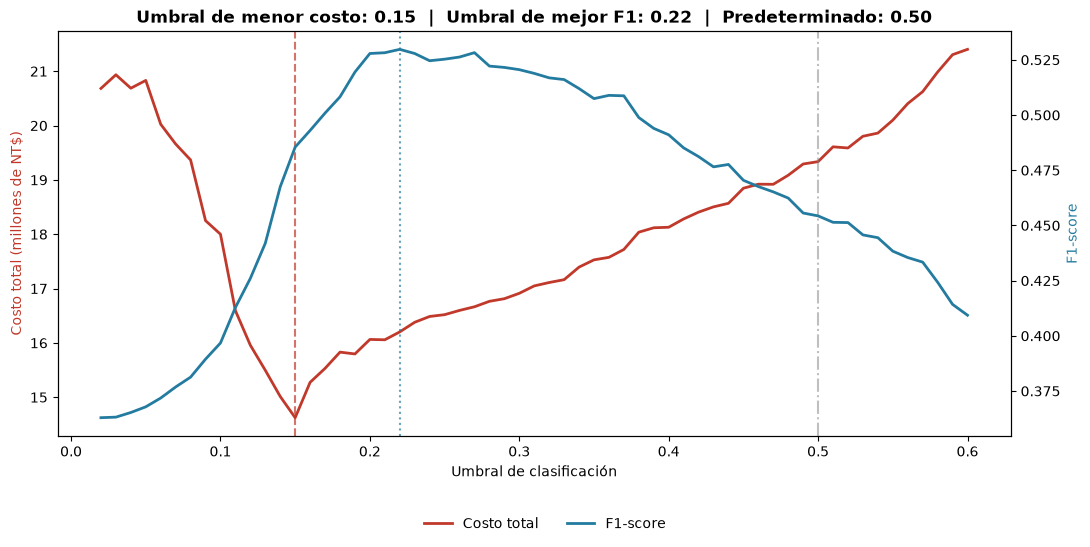

In [5]:
# ============================================================
# 4.1 GRÁFICO: COSTO Y F1-SCORE SEGÚN EL UMBRAL
# ============================================================

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(tabla_umbrales.index, tabla_umbrales["Costo (NT$)"] / 1e6, color="#C0392B", linewidth=2, label="Costo total")
ax1.set_xlabel("Umbral de clasificación")
ax1.set_ylabel("Costo total (millones de NT$)", color="#C0392B")

ax2 = ax1.twinx()
ax2.plot(tabla_umbrales.index, tabla_umbrales["F1-score"], color="#247BA0", linewidth=2, label="F1-score")
ax2.set_ylabel("F1-score", color="#247BA0")

ax1.axvline(umbral_costo, color="#C0392B", linestyle="--", alpha=0.7)
ax1.axvline(umbral_f1, color="#247BA0", linestyle=":", alpha=0.7)
ax1.axvline(0.50, color="grey", linestyle="-.", alpha=0.5)

ax1.set_title(f"Umbral de menor costo: {umbral_costo:.2f}  |  Umbral de mejor F1: {umbral_f1:.2f}  |  Predeterminado: 0.50",
              fontweight="bold")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Interpretación (completar después de ejecutar):**

- Con los supuestos definidos, el umbral de menor costo es 0.15, frente a 0.22 del mejor F1-score.
- Bajar el umbral detecta más incumplimientos (menos falsos negativos, que son los errores más costosos), a cambio de más falsas alarmas.
- El mejor F1 quedó en 0.22, dentro del rango evaluado en el notebook 04.

### 5. Evaluación final en el conjunto de prueba

Comparamos tres políticas sobre los 6.000 clientes de prueba, con el modelo entrenado por el equipo:
el umbral predeterminado (0.50), el de mejor F1 y el de menor costo.

In [6]:
# ============================================================
# 5. COMPARAR POLÍTICAS EN PRUEBA
# ============================================================

probabilidades_test = modelo_logistico.predict_proba(X_test)[:, 1]
exposicion_test = calcular_exposicion(X_test)
costo_test_sin_modelo = calcular_costo(y_test, np.zeros_like(probabilidades_test), 0.5, exposicion_test)

politicas = {
    "Predeterminado (0.50)": 0.50,
    f"Mejor F1 ({umbral_f1:.2f})": umbral_f1,
    f"Menor costo ({umbral_costo:.2f})": umbral_costo,
}

filas = []
for nombre, umbral in politicas.items():
    prediccion = (probabilidades_test >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, prediccion, labels=[0, 1]).ravel()
    costo = calcular_costo(y_test, probabilidades_test, umbral, exposicion_test)
    filas.append({
        "Política": nombre,
        "Recall": recall_score(y_test, prediccion, zero_division=0),
        "Precision": precision_score(y_test, prediccion, zero_division=0),
        "F1-score": f1_score(y_test, prediccion, zero_division=0),
        "Incumplidos detectados": vp,
        "Incumplidos no detectados": fn,
        "Falsas alarmas": fp,
        "Costo (NT$)": costo,
        "Ahorro vs. sin modelo": 1 - costo / costo_test_sin_modelo,
    })

tabla_politicas = pd.DataFrame(filas).set_index("Política")

print(f"Costo sin modelo en prueba: NT$ {costo_test_sin_modelo:,.0f}")
display(tabla_politicas.style.format({
    "Recall": "{:.2%}", "Precision": "{:.2%}", "F1-score": "{:.4f}",
    "Costo (NT$)": "{:,.0f}", "Ahorro vs. sin modelo": "{:.1%}"
}))

Costo sin modelo en prueba: NT$ 40,357,787


,Recall,Precision,F1-score,Incumplidos detectados,Incumplidos no detectados,Falsas alarmas,Costo (NT$),Ahorro vs. sin modelo
Política,,,,,,,,
Predeterminado (0.50),35.12%,66.19%,0.4589,466,861,238,"23,107,306",42.7%
Mejor F1 (0.22),55.84%,48.75%,0.5205,741,586,779,"19,812,023",50.9%
Menor costo (0.15),74.45%,34.86%,0.4749,988,339,1846,"18,841,850",53.3%


**Interpretación:**

- Frente a no usar modelo, la política de menor costo reduce las pérdidas estimadas en 53.3%.
- Frente al umbral predeterminado, detecta 522 incumplidos más, a cambio de 1,608 falsas alarmas adicionales.

### 6. Análisis de sensibilidad

Los valores de LGD y margen son supuestos. Si el umbral óptimo cambia poco al variarlos, la recomendación es robusta.

In [7]:
# ============================================================
# 6. SENSIBILIDAD DEL UMBRAL ÓPTIMO A LOS SUPUESTOS
# ============================================================

valores_lgd = [0.30, 0.45, 0.60, 0.75, 0.90]
valores_margen = [0.05, 0.10, 0.20]

sensibilidad = pd.DataFrame(index=[f"LGD {l:.0%}" for l in valores_lgd],
                            columns=[f"Margen {m:.0%}" for m in valores_margen], dtype=float)

for lgd in valores_lgd:
    for margen in valores_margen:
        costos = [calcular_costo(y_validacion, probabilidades_validacion, u, exposicion_validacion, lgd, margen)
                  for u in umbrales]
        sensibilidad.loc[f"LGD {lgd:.0%}", f"Margen {margen:.0%}"] = umbrales[int(np.argmin(costos))]

print("Umbral de menor costo según los supuestos:")
display(sensibilidad.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None))

Umbral de menor costo según los supuestos:


,Margen 5%,Margen 10%,Margen 20%
LGD 30%,0.15,0.19,0.33
LGD 45%,0.11,0.15,0.29
LGD 60%,0.09,0.15,0.19
LGD 75%,0.02,0.15,0.15
LGD 90%,0.02,0.11,0.15


**Interpretación:** El umbral óptimo se mueve entre **0.02** y **0.33**. Mientras más cueste un incumplimiento frente al margen perdido, más bajo debe ser el umbral.

### 7. Segmentación de clientes en bandas de riesgo

Además de la decisión sí/no, la probabilidad estimada permite ordenar a los clientes por riesgo y definir acciones diferenciadas.

In [8]:
# ============================================================
# 7. TABLA POR DECILES DE RIESGO
# ============================================================

resultados_test = pd.DataFrame({
    "probabilidad": probabilidades_test,
    "incumplio": np.asarray(y_test),
    "exposicion": exposicion_test,
})

# Decil 10 = clientes con mayor probabilidad estimada de incumplir
resultados_test["decil"] = pd.qcut(resultados_test["probabilidad"].rank(method="first"), 10, labels=range(1, 11))

tabla_deciles = (
    resultados_test.groupby("decil", observed=True)
    .agg(clientes=("incumplio", "size"),
         probabilidad_media=("probabilidad", "mean"),
         tasa_real=("incumplio", "mean"),
         incumplidos=("incumplio", "sum"),
         exposicion=("exposicion", "sum"))
    .sort_index(ascending=False)
)
tabla_deciles["% incumplidos capturados (acum.)"] = tabla_deciles["incumplidos"].cumsum() / tabla_deciles["incumplidos"].sum()

display(tabla_deciles.style.format({
    "probabilidad_media": "{:.1%}", "tasa_real": "{:.1%}",
    "exposicion": "{:,.0f}", "% incumplidos capturados (acum.)": "{:.1%}"
}))

,clientes,probabilidad_media,tasa_real,incumplidos,exposicion,% incumplidos capturados (acum.)
decil,,,,,,
10,600,72.6%,67.7%,406,"35,985,212",30.6%
9,600,39.8%,41.2%,247,"26,259,048",49.2%
8,600,22.9%,24.5%,147,"13,291,360",60.3%
7,600,17.7%,19.0%,114,"16,288,133",68.9%
6,600,15.4%,15.8%,95,"21,641,983",76.0%
5,600,13.9%,14.7%,88,"27,234,600",82.7%
4,600,12.6%,13.2%,79,"34,735,259",88.6%
3,600,11.2%,10.7%,64,"46,157,907",93.4%
2,600,9.4%,9.2%,55,"44,468,723",97.6%


,clientes,tasa_real,incumplidos,exposicion,% de clientes,% de incumplidos,Acción sugerida
banda,,,,,,,
Bajo (< 20 %),4278,12.8%,548,"236,356,378",71.3%,41.3%,Mantener condiciones; candidato a aumento de cupo
Medio (20 % - 50 %),1018,30.7%,313,"29,075,639",17.0%,23.6%,Seguimiento y recordatorios de pago; no aumentar cupo
Alto (≥ 50 %),704,66.2%,466,"44,944,280",11.7%,35.1%,Gestión preventiva de cobranza; revisar o congelar cupo


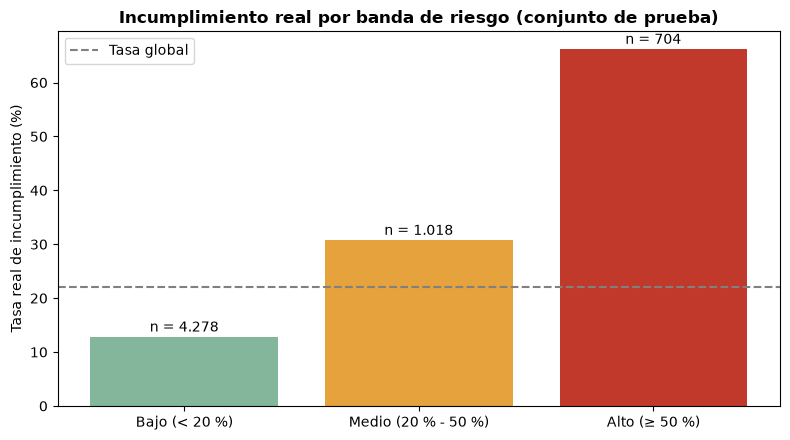

In [9]:
# ============================================================
# 7.1 BANDAS DE RIESGO Y ACCIONES SUGERIDAS
# ============================================================

cortes = [0, 0.20, 0.50, 1.0]
etiquetas = ["Bajo (< 20 %)", "Medio (20 % - 50 %)", "Alto (≥ 50 %)"]
acciones = {
    "Bajo (< 20 %)": "Mantener condiciones; candidato a aumento de cupo",
    "Medio (20 % - 50 %)": "Seguimiento y recordatorios de pago; no aumentar cupo",
    "Alto (≥ 50 %)": "Gestión preventiva de cobranza; revisar o congelar cupo",
}

resultados_test["banda"] = pd.cut(resultados_test["probabilidad"], bins=cortes, labels=etiquetas,
                                  include_lowest=True, right=False)

tabla_bandas = (
    resultados_test.groupby("banda", observed=False)
    .agg(clientes=("incumplio", "size"), tasa_real=("incumplio", "mean"),
         incumplidos=("incumplio", "sum"), exposicion=("exposicion", "sum"))
)
tabla_bandas["% de clientes"] = tabla_bandas["clientes"] / tabla_bandas["clientes"].sum()
tabla_bandas["% de incumplidos"] = tabla_bandas["incumplidos"] / tabla_bandas["incumplidos"].sum()
tabla_bandas["Acción sugerida"] = tabla_bandas.index.map(acciones)

display(tabla_bandas.style.format({
    "tasa_real": "{:.1%}", "exposicion": "{:,.0f}", "% de clientes": "{:.1%}", "% de incumplidos": "{:.1%}"
}))

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(tabla_bandas.index.astype(str), tabla_bandas["tasa_real"] * 100,
                color=["#83B69A", "#E6A23C", "#C0392B"])
for barra, n in zip(barras, tabla_bandas["clientes"]):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1, f"n = {n:,}".replace(",", "."), ha="center")
ax.axhline(resultados_test["incumplio"].mean() * 100, color="grey", linestyle="--", label="Tasa global")
ax.set_ylabel("Tasa real de incumplimiento (%)")
ax.set_title("Incumplimiento real por banda de riesgo (conjunto de prueba)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación:** La banda alta reúne el 11.7% de los clientes y el 35.1% de los incumplimientos. Si la gestión se concentra en las bandas media y alta, se cubre el 58.7% de los incumplidos revisando solo el 28.7% de la cartera.

## 8. Conclusiones y recomendaciones para el negocio

**Conclusiones**

1. El modelo de regresión logística ordena bien a los clientes por riesgo: la tasa real de incumplimiento crece de forma consistente entre las bandas baja, media y alta.
2. Elegir el umbral por costo, y no solo por F1-score, refleja que dejar pasar un incumplimiento cuesta varias veces más que una falsa alarma.
3. La recomendación de umbral se mantiene dentro de un rango acotado aunque cambien los supuestos de LGD y margen.

**Recomendaciones**

- Usar el modelo como **herramienta de priorización** (bandas de riesgo) y no como decisión automática de rechazo.
- Validar los supuestos de LGD y margen con el área financiera antes de fijar el umbral definitivo.
- Monitorear el desempeño periódicamente: los datos corresponden a Taiwán en 2005 y el comportamiento de pago cambia con el ciclo económico.

**Limitaciones y próximos pasos**

- Los costos son estimados; la base no incluye recuperaciones reales ni rentabilidad por cliente.
- Probar modelos adicionales (*Random Forest*, *Gradient Boosting*) y `class_weight="balanced"` como alternativa al ajuste de umbral.
- Revisar la calibración de las probabilidades si se van a usar para provisiones contables.